[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L8/BA_L8_ml_equity/BA_L8_ml_equity.ipynb)

# BA_L8_ml_equity: Trading the signals

*Quantlet of Lecture 8, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Cumulative log return after 10 basis points of transaction costs of strategies that are long Bitcoin when a walk-forward classifier (logit, random forest, XGBoost) predicts an up day, against buy-and-hold. EODHD daily Bitcoin data, test period 1 January 2020 - 22 October 2026.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['xgboost']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

The chart shows the cumulative log return (%) of each strategy over the test period: long Bitcoin when the predicted probability of an up day
$p_t$ exceeds 0.5, otherwise cash, with a cost of 10 basis points (bp) per change of position.
**How to read it**: a strategy that is long most of the time moves in parallel with buy-and-hold and inherits its drawdowns; the gains come in a few episodes.

In [5]:
# the slide charts use 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10})
SLIDE_GOLD = '#B8860B'

END = pd.Timestamp('2026-10-23')                       # last day of the lecture sample
btc = pd.read_csv(data_file('market', 'BTC-USD.CC.csv'), parse_dates=['date']).set_index('date').loc[:END]
r = (100 * np.log(btc['close'])).diff().dropna().loc['2015-01-01':]           # daily log return, %
lv = np.log(btc['volume'].replace(0, np.nan)).diff().reindex(r.index).fillna(0)  # daily change of log volume
print(f'Bitcoin daily log returns: {len(r)} days, {r.index[0].date()} to {r.index[-1].date()}')

Bitcoin daily log returns: 4314 days, 2015-01-01 to 2026-10-23


## Data and method

Daily Bitcoin closes and volumes from EODHD (course repository, `data/market`), to 23 October 2026; daily log returns in per cent,
$r_t = 100\,(\ln P_t - \ln P_{t-1})$.

The target is tomorrow's direction, $y_{t+1} = \mathbb{1}\{r_{t+1} > 0\}$. The 13 features $x_t$ are known at today's close: the returns of the
last three days, 5-, 20- and 60-day momentum (sums of returns), 5- and 20-day volatility, today's change in log volume and its 5-day mean,
the gaps (in %) between the price and its 50- and 200-day moving averages, and the day of the week. Three classifiers:

* logistic regression (logit), $P(y_{t+1} = 1 \mid x_t) = \Lambda(\beta_0 + x_t'\beta)$, $\Lambda(u) = 1/(1 + e^{-u})$, standardised features, ridge penalty;
* random forest: the average of 500 trees grown on bootstrap samples with random subsets of features;
* gradient boosting (XGBoost): additive trees $F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$ fitted to the gradient of the log-loss; $\eta = 0.05$, 300 trees of depth 3.

**Walk-forward design**: at each forecast origin, train on all data up to the origin, predict the next 63 days, move forward 63 days and refit.
Test period: 1 January 2020 – 22 October 2026 (the last day whose next-day return is known).

In [6]:
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

T0 = pd.Timestamp('2020-01-01')
COST = 0.10                                   # transaction cost, % per change of position (10 basis points)
c = btc['close'].reindex(r.index)
F = pd.DataFrame({'ret_1': r, 'ret_2': r.shift(1), 'ret_3': r.shift(2), 'mom_5': r.rolling(5).sum(), 'mom_20': r.rolling(20).sum(),
                  'mom_60': r.rolling(60).sum(), 'vol_5': r.rolling(5).std(), 'vol_20': r.rolling(20).std(),
                  'dvol': lv, 'dvol_5': lv.rolling(5).mean(), 'ma_gap_50': 100 * np.log(c / c.rolling(50).mean()),
                  'ma_gap_200': 100 * np.log(c / c.rolling(200).mean()), 'dow': r.index.dayofweek})
y = (r.shift(-1) > 0).astype(int)              # direction of tomorrow
ok = F.notna().all(axis=1) & r.shift(-1).notna()
F, y, rn = F[ok], y[ok], r.shift(-1)[ok]       # rn = tomorrow's return
Xv, yv, dates = F.values, y.values, F.index
test = np.where((dates >= T0) & (dates < END))[0]

MODELS = {'Logit': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
          'Random forest': lambda: RandomForestClassifier(n_estimators=500, max_depth=5, min_samples_leaf=20, random_state=1, n_jobs=-1),
          'XGBoost': lambda: XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                           random_state=1, verbosity=0)}
P = {m: np.full(len(dates), np.nan) for m in MODELS}
acc_in = {m: [] for m in MODELS}
for b0 in range(test[0], test[-1] + 1, 63):
    b1 = min(b0 + 63, test[-1] + 1)
    tr = np.arange(0, b0)
    for m, mk in MODELS.items():
        mdl = mk().fit(Xv[tr], yv[tr])
        P[m][b0:b1] = mdl.predict_proba(Xv[b0:b1])[:, 1]
        acc_in[m].append(((mdl.predict_proba(Xv[tr])[:, 1] > 0.5) == yv[tr]).mean())
    last_xgb = mdl                             # the last model in the loop is XGBoost
print(f'Test period: {dates[test[0]].date()} to {dates[test[-1]].date()}, T = {len(test)} days; '
      f'{len(range(test[0], test[-1] + 1, 63))} refits of each model')


def pt_test(yhat, yobs):
    """Pesaran-Timmermann (1992) test of directional accuracy: statistic and one-sided p-value."""
    T = len(yobs); py, px = yobs.mean(), yhat.mean()
    ph = (yhat == yobs).mean()
    ps = py * px + (1 - py) * (1 - px)
    v1 = ps * (1 - ps) / T
    v2 = ((2 * py - 1) ** 2 * px * (1 - px) / T + (2 * px - 1) ** 2 * py * (1 - py) / T + 4 * py * px * (1 - py) * (1 - px) / T ** 2)
    s = (ph - ps) / np.sqrt(v1 - v2)
    return s, stats.norm.sf(s)


def perf(pos, ret):
    """Net daily returns of a position path after costs, and summary statistics."""
    tc = COST * np.abs(np.diff(np.r_[0, pos]))
    g = pos * ret - tc
    eq = np.cumsum(g)
    d_log = np.max(np.maximum.accumulate(eq) - eq)          # largest fall of cumulative log return, log points
    return dict(SR=g.mean() / g.std(ddof=1) * np.sqrt(365), max_drawdown=100 * (1 - np.exp(-d_log / 100)), d_log=d_log), g


yt, rt = yv[test], rn.values[test]
G, rows = {}, {}
bh, G['Buy and hold'] = perf(np.ones(len(test)), rt)
rows['Always up / buy and hold'] = {'accuracy in-sample (%)': np.nan, 'accuracy out-of-sample (%)': 100 * yt.mean(), 'AUC': 0.5,
                                   'Brier score': yt.mean() * (1 - yt.mean()), 'PT p-value': np.nan, 'share of days long (%)': 100,
                                   'Sharpe ratio': bh['SR'], 'max drawdown (%)': bh['max_drawdown'], 'fall of cum. log return (log points)': bh['d_log']}
by_year = {}
for m in MODELS:
    p = P[m][test]; yh = (p > 0.5).astype(int)
    s, pv = pt_test(yh, yt)
    pf, G[m] = perf(yh.astype(float), rt)
    rows[m] = {'accuracy in-sample (%)': 100 * np.mean(acc_in[m]), 'accuracy out-of-sample (%)': 100 * (yh == yt).mean(),
               'AUC': roc_auc_score(yt, p), 'Brier score': np.mean((p - yt) ** 2), 'PT p-value': pv, 'share of days long (%)': 100 * yh.mean(),
               'Sharpe ratio': pf['SR'], 'max drawdown (%)': pf['max_drawdown'], 'fall of cum. log return (log points)': pf['d_log']}
    yrs = dates[test].year
    by_year[m] = {int(Y): 100 * ((yh == yt)[yrs == Y]).mean() for Y in np.unique(yrs)}
res_ml = pd.DataFrame(rows).T

Test period: 2020-01-01 to 2026-10-22, T = 2487 days; 40 refits of each model


## Performance and the chart

Daily net return $g_t$; annualised Sharpe ratio $= \sqrt{365}\,\bar g / s_g$; maximum drawdown $= 1 - e^{-D_{\log}/100}$, the largest fall of wealth
from its running peak, where $D_{\log}$ is the largest fall of the cumulative log return in log points (Lecture 2).

Trading the signals, test period, after 10 bp costs:
                          share of days long (%)  Sharpe ratio  max drawdown (%)  fall of cum. log return (log points)
Always up / buy and hold                  100.00          0.59             76.63                                145.39
Logit                                      85.44          0.72             68.62                                115.89
Random forest                              77.64          0.81             80.02                                161.07
XGBoost                                    64.86          0.63             76.94                                146.71


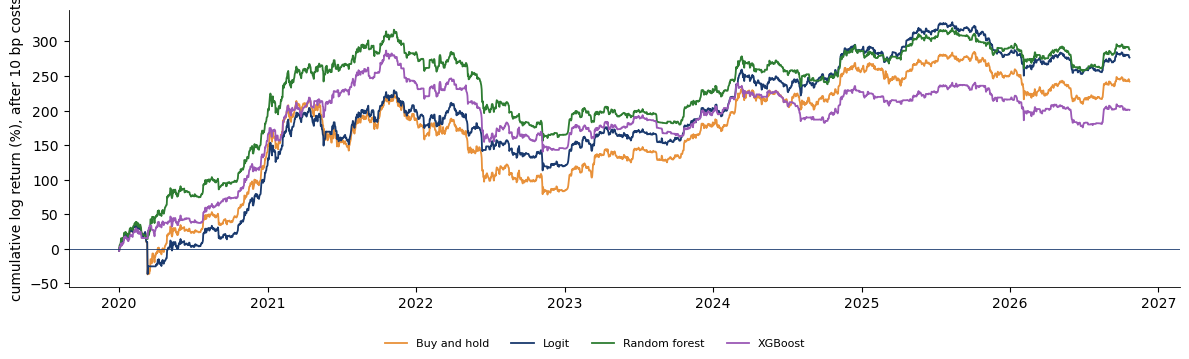

In [7]:
cols = ['share of days long (%)', 'Sharpe ratio', 'max drawdown (%)', 'fall of cum. log return (log points)']
print('Trading the signals, test period, after 10 bp costs:')
print(res_ml[cols].round(2).to_string())

fig, ax = plt.subplots(figsize=(12, 3.6))
for m, col in [('Buy and hold', BTC), ('Logit', BLUE), ('Random forest', GREEN), ('XGBoost', ETH)]:
    ax.plot(dates[test], np.cumsum(G[m]), color=col, lw=1.3, label=m)
ax.axhline(0, color=BLUE, lw=0.6)
ax.set_ylabel('cumulative log return (%), after 10 bp costs')
fig.legend(loc='lower center', ncol=4, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_fig(fig, 'ba_l8_ml_equity')